<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/440pg_Keras_Stock_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip  install finance-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]


In [3]:
# 1. 필요한 라이브러리 모듈 포함시키기

import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
#2. 데이터셋 로드

samsung = fdr.DataReader('005930','2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  194800  187000  194700   8729191  0.006202

[2660 rows x 6 columns]


In [10]:
openValues = samsung[['Open']]

In [13]:
#3. 특징값 정규화

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
scaled = scaler.fit_transform(openValues)

In [14]:
# 4. 훈련 데이터와 테스트 데이터의 분리

TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

In [15]:
# 5. 순차 훈련 데이터 생성

def make_sample(data, window):
  train = []
  target = []
  for i in range(len(data)-window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)

In [16]:
# 6. LSTM 구축

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1],1),
               activation='tanh',
               return_sequences=False)
)
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
# 7. 모델 학습

model.compile(optimizer = 'adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0030
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.2171e-04
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.6196e-05
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.9147e-05
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 7.9368e-05
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.7098e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 7.4528e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.7469e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.8190e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.5931e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.5740e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.2232e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 6.1386e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.

In [18]:
# 8. 테스트셋을 이용하여 미래 주가 예측

X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


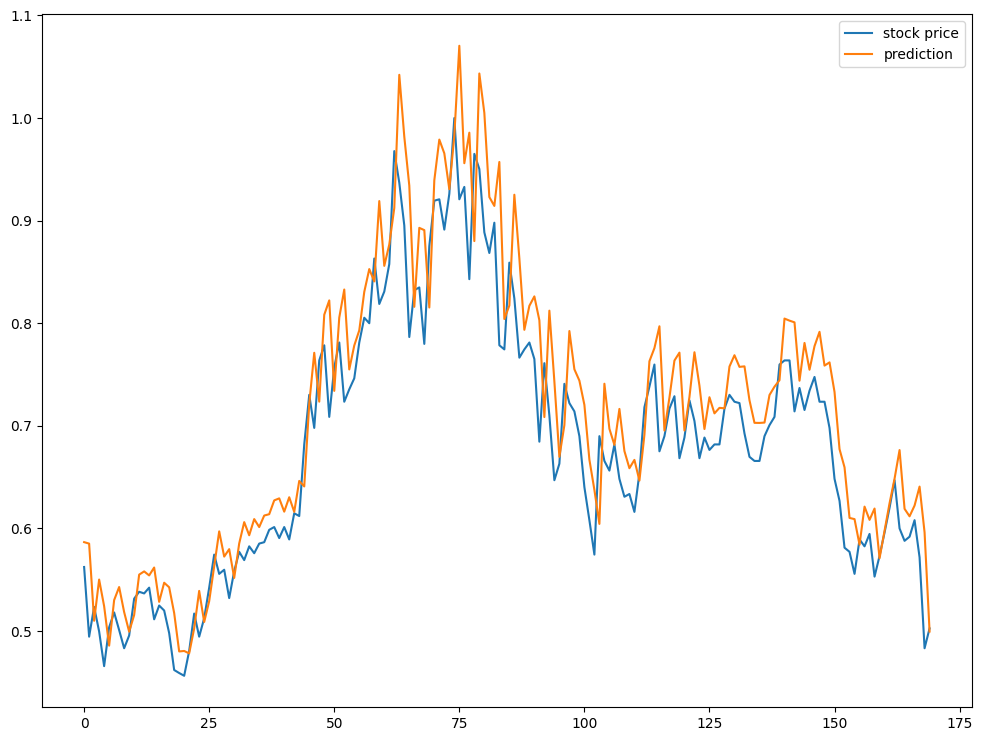

In [19]:
# 9. 그래프 그리기

import matplotlib.pyplot as plt
plt.figure(figsize=(12,9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='prediction')
plt.legend()
plt.show()